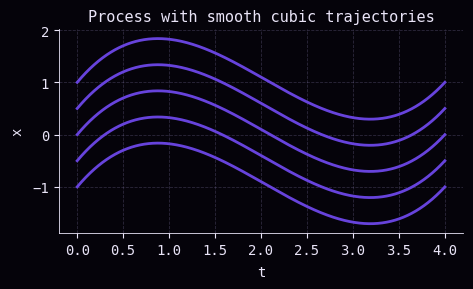

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import sigalg as sa

sa.style.set_style("black")

n_trajectories = 5
Delta_t = 0.001


def cubics(t: np.ndarray) -> np.ndarray:  # noqa: D103
    polys = [
        lambda t_i, a=a: 0.25 * t_i * (t_i - 2.1) * (t_i - 4) + a
        for a in np.linspace(-1, 1, n_trajectories)
    ]
    return np.array([p(t_i) for p, t_i in zip(polys, t)])


T = sa.Time.continuous(start=0, stop=4, dt=Delta_t)

X = sa.StochasticProcess.from_time(
    T, n_trajectories=n_trajectories
).apply_to_components(cubics, name="X")

_, ax = plt.subplots(figsize=(5, 3))
X.plot_trajectories(ax, y_label="x", x_label="t", colors=[sa.style.purple])
ax.set_title("Process with smooth cubic trajectories")

plt.tight_layout()
plt.show()

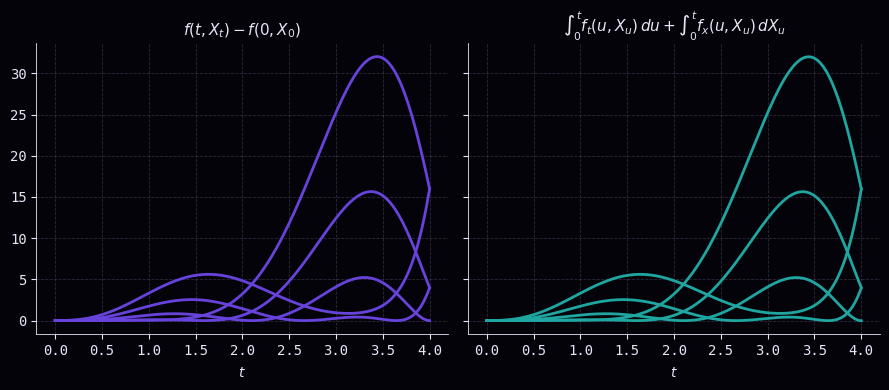

In [9]:
t = sa.StochasticProcess.from_time(process=X, name="t")

ito_integral = sa.ProcessTransforms.ito_integral

f_t = 2 * t * X**2
f_x = 2 * t**2 * X

increment = ito_integral(integrator=t**2 * X**2)
int_f_t = ito_integral(f_t, t)
int_f_x = ito_integral(f_x, X)

_, axes = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(9, 4))
increment.plot_trajectories(axes[0], colors=[sa.style.purple])
(int_f_t + int_f_x).plot_trajectories(axes[1], colors=[sa.style.teal])

axes[0].set_title(r"$f(t, X_t) - f(0, X_0)$")
axes[1].set_title(r"$\int_0^t f_t(u, X_u) \, du + \int_0^t f_x(u, X_u) \, dX_u$")
axes[0].set_xlabel(r"$t$")
axes[1].set_xlabel(r"$t$")

plt.tight_layout()
plt.show()

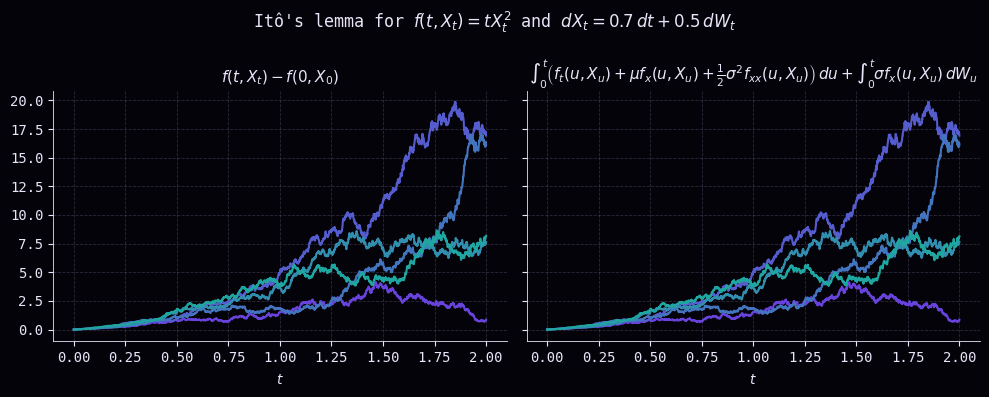

In [24]:
import matplotlib.pyplot as plt
import sigalg as sa

mu = 0.7
sigma = 0.5
T = sa.Time.continuous(start=0, stop=2, dt=0.001)

X = sa.BrownianMotion.generate(
    drift=mu,
    diffusion=sigma,
    initial_state=1,
    n_trajectories=5,
    index=T,
    random_state=42,
)

W = X.driver
t = sa.StochasticProcess.from_time(process=X)

f_t = X**2
f_x = 2 * t * X
f_tt = 0.0
f_xx = 2 * t

increment = ito_integral(integrator=t * X**2)
int_dt = ito_integral(f_t + mu * f_x + (1 / 2) * sigma**2 * f_xx, t)
int_dw = ito_integral(sigma * f_x, W)

fig, axes = plt.subplots(ncols=2, sharex=True, sharey=True, figsize=(10, 4))

increment.plot_trajectories(
    axes[0], colors=[sa.style.purple, sa.style.teal], plot_kwargs={"linewidth": 1.5}
)
(int_dt + int_dw).plot_trajectories(
    axes[1], colors=[sa.style.purple, sa.style.teal], plot_kwargs={"linewidth": 1.5}
)

axes[0].set_title(r"$f(t, X_t) - f(0, X_0)$")
axes[1].set_title(
    r"$\int_0^t \left( f_t(u, X_u)+\mu f_x(u,X_u) + \frac{1}{2}\sigma^2 f_{xx}(u,X_u) \right) \, du + \int_0^t \sigma f_x(u, X_u) \, dW_u$"
)
axes[0].set_xlabel(r"$t$")
axes[1].set_xlabel(r"$t$")

fig.suptitle(r"Itô's lemma for $f(t,X_t) = tX_t^2$ and $dX_t = 0.7\, dt + 0.5 \, dW_t$")
plt.tight_layout()
plt.show()

In [40]:
import numpy as np
from sigalg import BrownianMotion, ProcessTransforms, StochasticProcess, Time

mu = 0.7
sigma = 0.5
T = Time.continuous(start=0, stop=1, dt=0.001)

X = BrownianMotion.generate(
    drift=mu,
    diffusion=sigma,
    initial_state=1,
    n_trajectories=5,
    index=T,
    random_state=42,
)
t = StochasticProcess.from_time(process=X)
W = X.driver

ito_integral = ProcessTransforms.ito_integral

np.allclose(
    ito_integral(integrator=X),
    mu * ito_integral(integrator=t) + sigma * ito_integral(integrator=W),
)

True